# Experiment 05: Language Modeling
**COMP-441L Natural Language Processing**

**Objectives**

- Understand what a language model is: it gives the probability of the next word.
- Build and compare three kinds of language model: n-grams (counting), RNN and LSTM (neural networks), and a pre-trained Transformer.
- Measure and compare models fairly with perplexity.

**How to use this notebook**

- Parts 01 to 03 are fully worked examples. Run the cells from top to bottom and read the text above each cell.
- The **Student Tasks** are at the very end. Use the functions built above, and write the new code yourself in the empty cells.
- For Part 02, upload `nursery_rhymes.txt` to the Colab files panel (left sidebar) first.

> Completed version: Student Tasks 1 to 4 are filled in below (all cells were run, outputs visible). `combined_corpus.txt` is written by Task 2.

In [1]:
import re, math, random, time
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(7)
np.random.seed(7)

# Part 01: N-gram Models

**Big idea:** a language model guesses the next word. An n-gram model does it by **counting** which words followed which in the text it has seen.

### 1.1 Clean and tokenize the corpus

We lowercase the text, remove punctuation, split it into words, and add `<s>` (start) and `</s>` (end) to every sentence, so the model can learn how sentences begin and end.

In [2]:
corpus = """I am Sam.
Sam I am.
I do not like green eggs and ham.
I like to play football.
I am going to school today.
She loves playing the piano.
The cat sat on the mat.
The dog chased the cat."""

def clean(text):
    return re.sub(r"[^a-z\s]", "", text.lower())

sentences = []
for line in corpus.split("\n"):
    words = clean(line).split()
    sentences.append(["<s>"] + words + ["</s>"])

for s in sentences:
    print(s)
print("Vocabulary size:", len(set(w for s in sentences for w in s if w not in ("<s>", "</s>"))))

['<s>', 'i', 'am', 'sam', '</s>']
['<s>', 'sam', 'i', 'am', '</s>']
['<s>', 'i', 'do', 'not', 'like', 'green', 'eggs', 'and', 'ham', '</s>']
['<s>', 'i', 'like', 'to', 'play', 'football', '</s>']
['<s>', 'i', 'am', 'going', 'to', 'school', 'today', '</s>']
['<s>', 'she', 'loves', 'playing', 'the', 'piano', '</s>']
['<s>', 'the', 'cat', 'sat', 'on', 'the', 'mat', '</s>']
['<s>', 'the', 'dog', 'chased', 'the', 'cat', '</s>']
Vocabulary size: 27


##Why Do We Add Them? the tags
###Marking Boundaries:
###Signaling When to Stop (Generation)

### 1.2 A reusable preprocessing function

Later we need the same cleaning for unigram, bigram and trigram models. An n-gram model looks at `n - 1` previous words, so each sentence gets `n - 1` start tokens.
This function also splits at `.` `!` `?` and keeps apostrophes (*don't* stays *don't*).

In [3]:
def preprocess(text, n=2):
    """Return a list of padded sentences (each a list of tokens)."""
    out = []
    for sent in re.split(r"[.!?]+", text):
        words = re.sub(r"[^a-z'\s]", "", sent.lower()).split()
        words = [w.strip("'") for w in words]
        words = [w for w in words if w]
        if words:
            out.append(["<s>"] * (n - 1) + words + ["</s>"])
    return out

print(preprocess("I don't like eggs. Do you? Yes!", 2))
print(preprocess("I don't like eggs.", 3))

[['<s>', 'i', "don't", 'like', 'eggs', '</s>'], ['<s>', 'do', 'you', '</s>'], ['<s>', 'yes', '</s>']]
[['<s>', '<s>', 'i', "don't", 'like', 'eggs', '</s>']]


### 1.3 Unigram model: count every word

A unigram model ignores context. The probability of a word is how many times it appears divided by the total number of words.

In [4]:
uni_counts = Counter(w for s in sentences for w in s if w != "<s>")
total = sum(uni_counts.values())

table = pd.DataFrame(uni_counts.most_common(8), columns=["word", "count"])
table["probability"] = (table["count"] / total).round(3)
print(table)
print("All probabilities add up to:", round(sum(n / total for n in uni_counts.values()), 6))

words = list(uni_counts)
weights = [uni_counts[w] for w in words]
print("Random text:", " ".join(random.choices(words, weights=weights, k=8)))

   word  count  probability
0  </s>      8        0.163
1     i      5        0.102
2   the      5        0.102
3    am      3        0.061
4   sam      2        0.041
5  like      2        0.041
6    to      2        0.041
7   cat      2        0.041
All probabilities add up to: 1.0
Random text: </s> am school i to </s> i and


### 1.4 Bigram model: what comes after a word?

A bigram model looks at **one** previous word. P(next | previous) = count(previous next) ÷ count(previous).

In [5]:
bigram_counts = {}
for s in sentences:
    for a, b in zip(s, s[1:]):
        bigram_counts.setdefault(a, Counter())[b] += 1

after_i = bigram_counts["i"]
for word, n in after_i.most_common():
    print(f"P({word} | i) = {n}/{sum(after_i.values())} = {n / sum(after_i.values()):.2f}")

P(am | i) = 3/5 = 0.60
P(do | i) = 1/5 = 0.20
P(like | i) = 1/5 = 0.20


### 1.5 N-grams of any size

The bigram code above only works for n = 2. These two functions work for **any n**:

- `count_ngrams(sentences, n)` returns a dictionary: context tuple → `Counter` of the words that followed it. For a trigram the context is two words, for a unigram it is the empty tuple `()`.
- `next_probs(counts, context)` turns those counts into probabilities.

We then build the unigram, bigram and trigram models used in the rest of Part 01.

In [6]:
def count_ngrams(sentences, n):
    counts = defaultdict(Counter)
    for s in sentences:
        for i in range(n - 1, len(s)):
            context = tuple(s[i - n + 1:i])
            counts[context][s[i]] += 1
    return counts

def next_probs(counts, context):
    c = counts.get(tuple(context), Counter())
    total = sum(c.values())
    return {w: n / total for w, n in c.items()} if total else {}

uni = count_ngrams(preprocess(corpus, 1), 1)
bi  = count_ngrams(preprocess(corpus, 2), 2)
tri = count_ngrams(preprocess(corpus, 3), 3)

print("After 'i'        :", next_probs(bi, ("i",)))
print("After 'sam i'    :", next_probs(tri, ("sam", "i")))
print("After 'the cat'  :", next_probs(tri, ("the", "cat")))

After 'i'        : {'am': 0.6, 'do': 0.2, 'like': 0.2}
After 'sam i'    : {'am': 1.0}
After 'the cat'  : {'sat': 0.5, '</s>': 0.5}


### 1.6 Generating text

To generate a sentence, start with `n - 1` copies of `<s>`, pick the next word at random using the probabilities, add it, and repeat until `</s>` is picked.
Compare how the text changes from unigram to trigram.

In [7]:
def generate(counts, n, max_len=15):
    history = ["<s>"] * (n - 1)
    out = []
    for _ in range(max_len):
        context = tuple(history[len(history) - (n - 1):])
        probs = next_probs(counts, context)
        if not probs:
            break
        word = random.choices(list(probs), weights=list(probs.values()))[0]
        if word == "</s>":
            break
        out.append(word)
        history.append(word)
    return " ".join(out)

for n, model in [(1, uni), (2, bi), (3, tri)]:
    print("n =", n)
    for _ in range(3):
        print("   ", generate(model, n))

n = 1
    i like i i like the am
    going mat play not dog i cat
    am am
n = 2
    the piano
    she loves playing the piano
    she loves playing the cat sat on the cat
n = 3
    sam i am sam
    i am going to school today
    the dog chased the cat


### 1.7 Perplexity in one minute

**Perplexity** answers: *"at each step, how many words is the model choosing between?"*

- Every next word has probability 0.1: the model is choosing between 10 words, so perplexity is **10**.
- Every next word has probability 0.5: it is choosing between 2 words, so perplexity is **2**.

**Lower is better.** Formula: `exp( −average of log(probability) )`.
###perplexity is an intrinsic evaluation metric used to measure the performance and uncertainty of a language model

In [8]:
def perplexity_from_probs(probs):
    return math.exp(-sum(math.log(p) for p in probs) / len(probs))

print(perplexity_from_probs([0.1] * 5))                   # about 10
print(perplexity_from_probs([0.5] * 5))                   # about 2
print(perplexity_from_probs([0.5, 0.5, 0.1, 0.5, 0.5]))   # one hard word raises it

9.999999999999998
2.0
2.7594593229224293


# Part 02: Neural Network Models (TensorFlow)

**Big idea:** instead of counting, a neural network **learns** which word comes next. We give it 4 words and ask for the 5th.
Settings for every model: embedding size 128, 256 neurons in the recurrent layer, softmax output, 100 epochs.

##Embedding represent: 128 or 256 hidden scores for the vector
cat → one vector: [0.8, -0.2, 0.5, ... , 0.1]
            <br>  └── 128 numbers in total ──┘  
###Softmax uses that memory to give a probability for every possible next word.
###Recurrent layer

“Recurrent” means the layer repeats the same step for each word and passes its memory forward. In your code, it’s layers.SimpleRNN(256) or layers.LSTM(256).

###What each neuron represents

A single neuron usually has no clear meaning. For example, neuron 10 doesn’t simply mean “a person’s name”, and neuron 50 doesn’t mean “past tense”. Together, the 256 numbers form a summary of the words read so far, and the model learns that summary because it helps predict the next word.

###Note:
Neural language models still use probability and math, but they do not just count exact word strings the way classical N-gram statistical models do.
When people say neural models use "patterns," they mean the model maps words and context into a continuous geometric space (embeddings) and learns distributed, generalized features

### 2.1 Load the nursery rhymes

We clean the text, give every word a number, and keep the number 0 for unknown words.

In [9]:
import os
if not os.path.exists("nursery_rhymes.txt"):
    raise FileNotFoundError("Upload nursery_rhymes.txt in the Colab files panel (left sidebar), then run again.")

tokens = clean(open("nursery_rhymes.txt", encoding="utf-8").read()).split()
word2idx = {w: i + 1 for i, w in enumerate(sorted(set(tokens)))}
idx2word = {i: w for w, i in word2idx.items()}
VOCAB = len(word2idx) + 1
ids = [word2idx[w] for w in tokens]
print(word2idx)
print(idx2word)
print("Tokens:", tokens[:10])
print(ids)
print("Words:", len(tokens), "| Vocabulary:", VOCAB)

{'a': 1, 'above': 2, 'after': 3, 'again': 4, 'all': 5, 'along': 6, 'and': 7, 'another': 8, 'any': 9, 'are': 10, 'as': 11, 'at': 12, 'away': 13, 'b': 14, 'baa': 15, 'baby': 16, 'bags': 17, 'bake': 18, 'bakers': 19, 'bed': 20, 'beside': 21, 'bitsy': 22, 'black': 23, 'blind': 24, 'boat': 25, 'bowl': 26, 'boy': 27, 'bridge': 28, 'broke': 29, 'but': 30, 'cake': 31, 'called': 32, 'came': 33, 'can': 34, 'carving': 35, 'cat': 36, 'children': 37, 'climbed': 38, 'clock': 39, 'cole': 40, 'come': 41, 'couldnt': 42, 'cow': 43, 'crown': 44, 'crying': 45, 'curds': 46, 'cut': 47, 'dame': 48, 'day': 49, 'diamond': 50, 'dickory': 51, 'diddle': 52, 'dish': 53, 'dock': 54, 'dog': 55, 'down': 56, 'downstairs': 57, 'dream': 58, 'dried': 59, 'dumpty': 60, 'eating': 61, 'eight': 62, 'everywhere': 63, 'fair': 64, 'fall': 65, 'falling': 66, 'farmers': 67, 'fast': 68, 'fell': 69, 'fetch': 70, 'fiddle': 71, 'fiddlers': 72, 'fleece': 73, 'for': 74, 'frightened': 75, 'full': 76, 'gently': 77, 'go': 78, 'great': 79,

In [10]:
#set(tokens) removes duplicate words.

#sorted(...) sorts the distinct words alphabetically.

#enumerate(...) assigns an index to each word.

#i + 1 starts IDs at 1 instead of 0.
# for ids
#tokens = ["twinkle", "twinkle", "little", "star"]
#ids = [203, 203, 91, 174]  # illustrative IDs   The same word always receives the same ID within this vocabulary.

### 2.2 Training examples and the train/test split

We slide a window of 4 words over the text. The 4 words are the input and the next word is the answer.

We split **by position**: the first 80% of the text trains the model and the last 20% tests it. A random split would put almost identical overlapping windows (they share 3 of 4 words) in both sets and hide overfitting.

In [11]:
SEQ_LEN = 4

def make_windows(ids, seq_len):
  #make_windows: cuts the text into question and answer pairs. The network learns by being
  #shown a few words (the question) and the next word (the answer). This function builds all of those pairs.
    X, y = [], []
    for i in range(len(ids) - seq_len):
        X.append(ids[i:i + seq_len])
        y.append(ids[i + seq_len])
    return np.array(X), np.array(y)

def split_by_position(X, y, frac): #split_by_position: divides the pairs into training and test sets
    cut = int(frac * len(X))
    return X[:cut], X[cut:], y[:cut], y[cut:]

X, y = make_windows(ids, SEQ_LEN)
X_train, X_test, y_train, y_test = split_by_position(X, y, 0.8)   # 80% of 471 = 376
print("the X: ", X)
print("the y: ", y)
print("Train:", X_train.shape, "Test:", X_test.shape)
print(" ".join(idx2word[j] for j in X[0]), "->", idx2word[y[0]])

print("Y Train:", y_train.shape, "Y_Test:", y_test.shape)

the X:  [[182 182 110 164]
 [182 110 164  90]
 [110 164  90  92]
 ...
 [132 173 170 200]
 [173 170 200   1]
 [170 200   1  35]]
the y:  [ 90  92 201 192 205  10 183   2 172 203 158  86 109   1  50  93 172 156
 182 182 110 164  90  92 201 192 205  10  91  60 152 134   1 185  91  60
  80   1  79  65   5 172 102  89   7   5 172 102 119  42 144  91 178   4
  98   7  99 191 183 172  87 177  70   1 139 131 189  98  69  56   7  29
  88  44   7  99  33 181   3  15  15  23 154  81 205   9 202 204 155 204
 155 175  17  76 135  74 172 117 135  74 172  48   7 135  74 172 110  27
 195 111  56 172 106 116  80   1 110 105  96  73 187 194  11 157   7  63
 171 116 191 172 105 187 169 177  78 110 123 126 152 134   1 180  61  83
  46   7 193   6  33   1 160 195 152  56  21  83   7  75 123 126  13  84
  52  52 172  36   7 172  71 172  43 100 138 172 124 172 110  55 107 177
 153 167 162   7 172  53 146  13 200 172 161  97  22 160  38 183 172 189
 163  56  33 172 145   7 188 172 160 136 136  33 172 168   7 

##1

	Accuracy	Meaning
#Training:
 	97.6%	The model remembered the text it practised on

#Test:
  1.1%	It almost completely failed on text it hadn’t seen

Without a test set, you would see only 97.6% and think the model was excellent. The test set shows that it mostly memorized the text.

##How to read the two scores
Training score	Test score	        Meaning
High          	High	               The model learned well
High	          Low	Overfitting:     it memorized the training data
Low           	Low	Underfitting:    it hasn’t learned enough

##2
##What the four variables mean

X means input and y means the correct answer. The second part of each name tells you which set it belongs to:

#Variable	What it contains	Used for
#X_train
	Four-word inputs for training:	The model learns from these
#y_train
	Correct next words for X_train:	The model checks its predictions and corrects its weights
#X_test
	Four-word inputs for testing:	The model makes predictions on these
#y_test
	Correct next words for X_test:	Used to calculate the test score, not to train

##3:
Clean text and convert words to IDs <br>
              ↓<br>
Your cell: make X and y, then split them<br>
              ↓<br>
Build the model (RNN or LSTM)<br>
              ↓<br>
Train with X_train and y_train<br>
              ↓<br>
Check with X_test and y_test<br>

### 2.3 Train a SimpleRNN

A SimpleRNN reads the 4 words one by one and keeps a small memory. Layers: Embedding (word to 128 numbers), SimpleRNN (256), Dense with softmax (a probability for every word in the vocabulary).

In [12]:
import tensorflow as tf
from tensorflow.keras import layers, models
tf.random.set_seed(7)
EPOCHS = 100

def build_model(kind, units=256):
    recurrent = layers.SimpleRNN(units) if kind == "rnn" else layers.LSTM(units)
    model = models.Sequential([
        layers.Input(shape=(SEQ_LEN,)),
        layers.Embedding(VOCAB, 128),
        recurrent,
        layers.Dense(VOCAB, activation="softmax"),
    ])
    model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model

rnn = build_model("rnn")
rnn.summary()
rnn_hist = rnn.fit(X_train, y_train, epochs=EPOCHS, batch_size=32,
                   validation_data=(X_test, y_test), verbose=0)
print("Train accuracy:", round(rnn_hist.history["accuracy"][-1], 3))
print("Test accuracy :", round(rnn_hist.history["val_accuracy"][-1], 3))

I0000 00:00:1794315597.861911   20888 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794315597.912877   20888 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794315599.031374   20888 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 4, 128)         │        26,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 256)            │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 207)            │        53,199 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,255 (696.31 KB)

 Trainable params: 178,255 (696.31 KB)

 Non-trainable params: 0 (0.00 B)

Train accuracy: 0.977
Test accuracy : 0.012


##Output shape, reading (None, 4, 128):

None is the batch size, the number of windows processed together. It stays open because it can be any number.
4 is the number of words in the window.
128 is the length of each word’s vector.

So after the Embedding layer you have 4 vectors of 128 numbers each. After the SimpleRNN layer, (None, 256) means each window is squeezed into one memory of 256 numbers. After the Dense layer, (None, 207) is one probability per word in the vocabulary.
##Trainable params (178,255): the weights that training  is allowed to change. Here that is all of them.

##Non-trainable params (0): weights that stay fixed during training. There are none here. They appear when you freeze a layer, for example when you use a pre-trained embedding and don’t want to change it, or in some layers that store running statistics (such as BatchNorm).

In [13]:
##Code part for ML / DL
#optimizer="adam" adjusts the model's parameters during training.

#loss="sparse_categorical_crossentropy" measures how well the predicted probabilities match the correct word IDs.

#metrics=["accuracy"] tracks how often the most probable predicted ID matches the correct target

#build_model("rnn") creates the SimpleRNN model.

#summary() displays the layers, output shapes and parameter counts.

#fit() starts training.

#batch_size=32 processes up to 32 training examples per batch.

#validation_data evaluates the model on the held-out examples after each epoch.

#verbose=0 suppresses the usual training progress output.

#model	Which architecture was trained

#parameters	Number of trainable and non-trainable model parameters

#train_acc	Accuracy on training examples

#test_acc	Accuracy on the held-out examples, called validation accuracy during fitting



### 2.4 Train an LSTM and compare

An LSTM has gates that decide what to remember and what to forget, so it has about four times as many recurrent parameters as a SimpleRNN.

The **baseline** is a model that always predicts the most common word. A neural network that cannot beat it has not learned to generalize.
Training accuracy is very high but test accuracy is very low, because the test part contains rhymes the models never saw. That gap is **overfitting**.

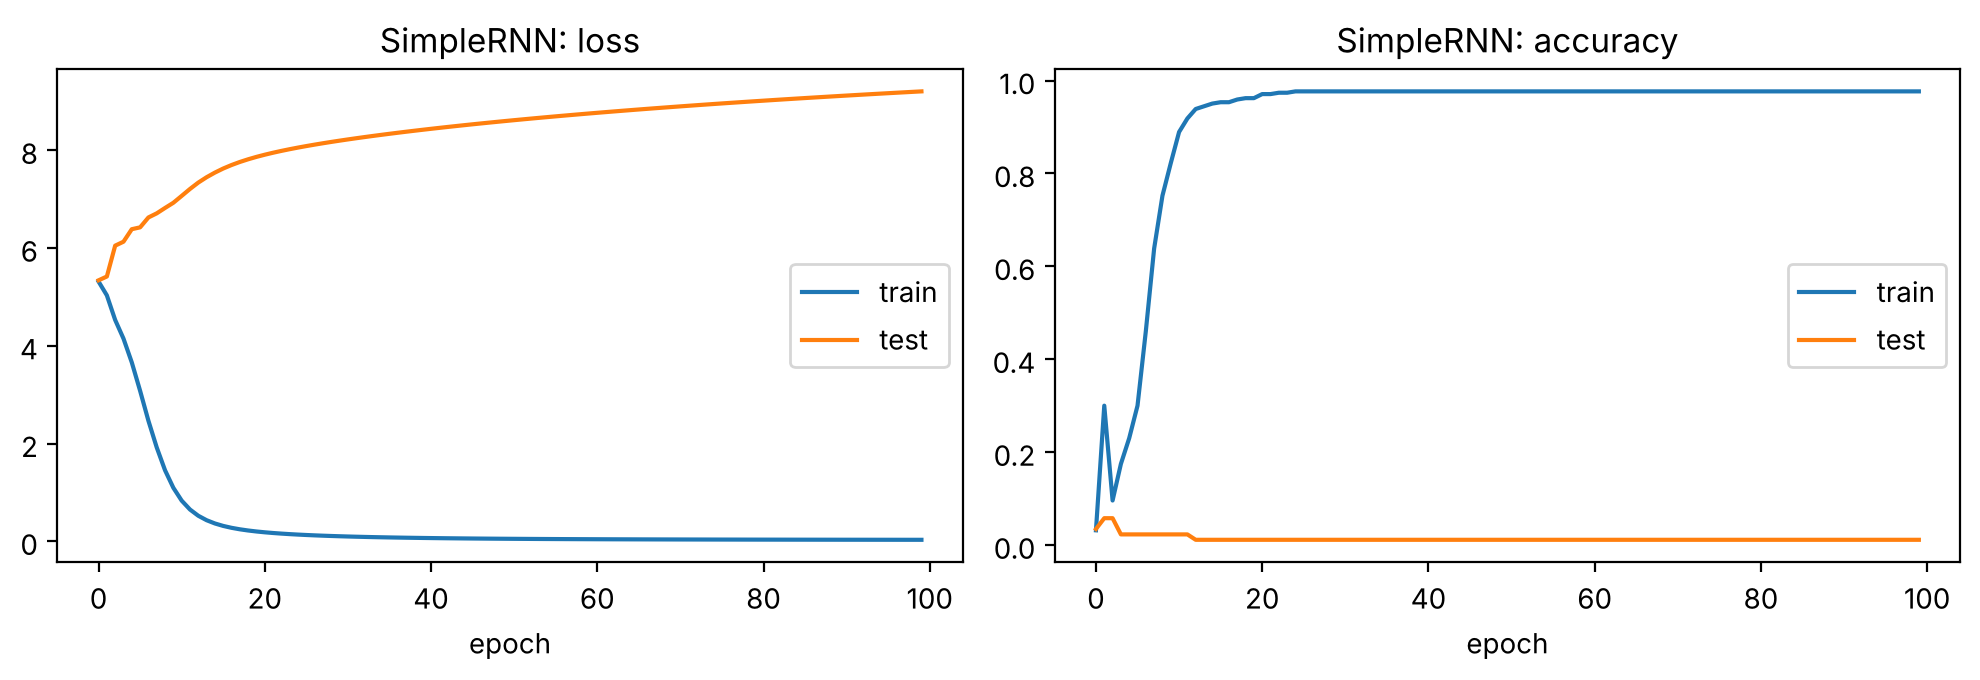

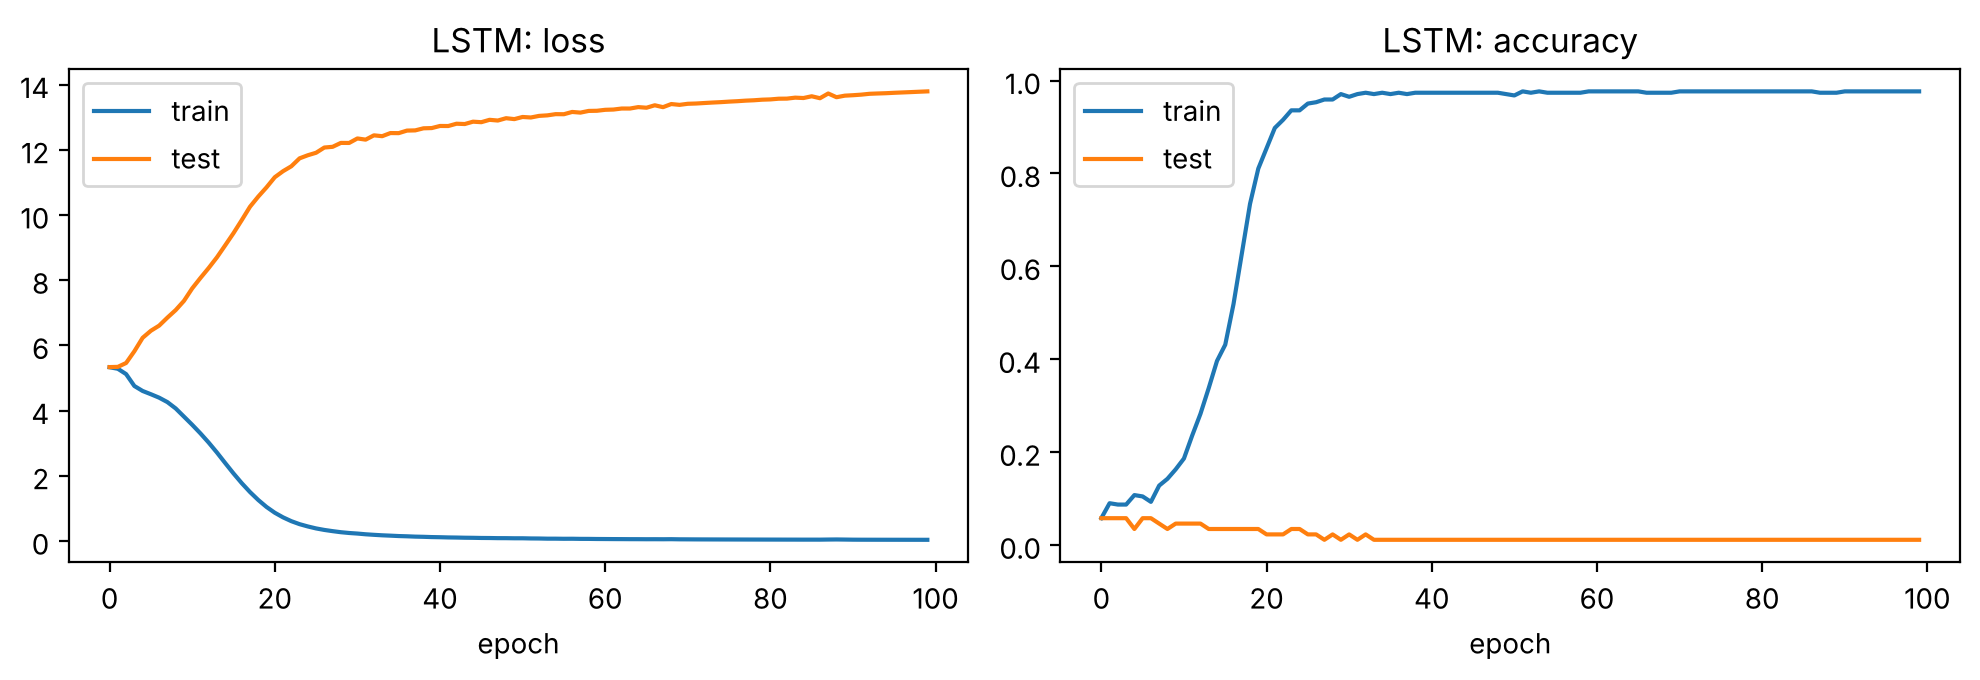

       model  parameters  train_acc  test_acc
0  SimpleRNN      178255      0.977     0.012
1       LSTM      473935      0.977     0.012
Baseline (always predict the most common word): 0.058


In [14]:
lstm = build_model("lstm")
lstm_hist = lstm.fit(X_train, y_train, epochs=EPOCHS, batch_size=32,
                     validation_data=(X_test, y_test), verbose=0)

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(hist.history["loss"], label="train")
    ax[0].plot(hist.history["val_loss"], label="test")
    ax[0].set_title(title + ": loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train")
    ax[1].plot(hist.history["val_accuracy"], label="test")
    ax[1].set_title(title + ": accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(rnn_hist, "SimpleRNN")
plot_history(lstm_hist, "LSTM")

comparison = pd.DataFrame([
    {"model": "SimpleRNN", "parameters": rnn.count_params(),
     "train_acc": round(rnn_hist.history["accuracy"][-1], 3), "test_acc": round(rnn_hist.history["val_accuracy"][-1], 3)},
    {"model": "LSTM", "parameters": lstm.count_params(),
     "train_acc": round(lstm_hist.history["accuracy"][-1], 3), "test_acc": round(lstm_hist.history["val_accuracy"][-1], 3)},
])
most_common_word = Counter(y_train.tolist()).most_common(1)[0][0]
baseline = round(float(np.mean(y_test == most_common_word)), 3)
print(comparison)
print("Baseline (always predict the most common word):", baseline)

##Why a model that knows nothing gives 5.3

Before training, the weights are random, so the model has no preference. It spreads its probability almost equally over all 207 words. Each word gets about:

1 / 207 = 0.00483

So the correct word gets a probability of about 0.0048, and:

loss = −ln(1/207) = ln(207) = 5.33

That is the 5.3 on the graph. It is the loss of random guessing among 207 words.

A simpler way to picture it
* A coin flip has 2 choices, so a random guess gives loss ln(2) = 0.69.
* A dice roll has 6 choices, so a random guess gives loss ln(6) = 1.79.
* A vocabulary of 207 words gives loss ln(207) = 5.33.



After training, the model gives a probability to every word in the vocabulary. There are two ways to pick the next word:

##Greedy: always take the highest-probability word. This is safe, but the same seed always gives the same text.
##Sampling: pick a word at random, weighted by the probabilities. A word with 70% is picked 70% of the time, so the text varies.
##What temperature does
##Temperature
t changes the shape of the probabilities before sampling. In the code, log(p) / t followed by softmax is the same as raising each probability to the power 1/t and re-normalizing. Take three words with probabilities 0.7, 0.2 and 0.1:

![image.png]()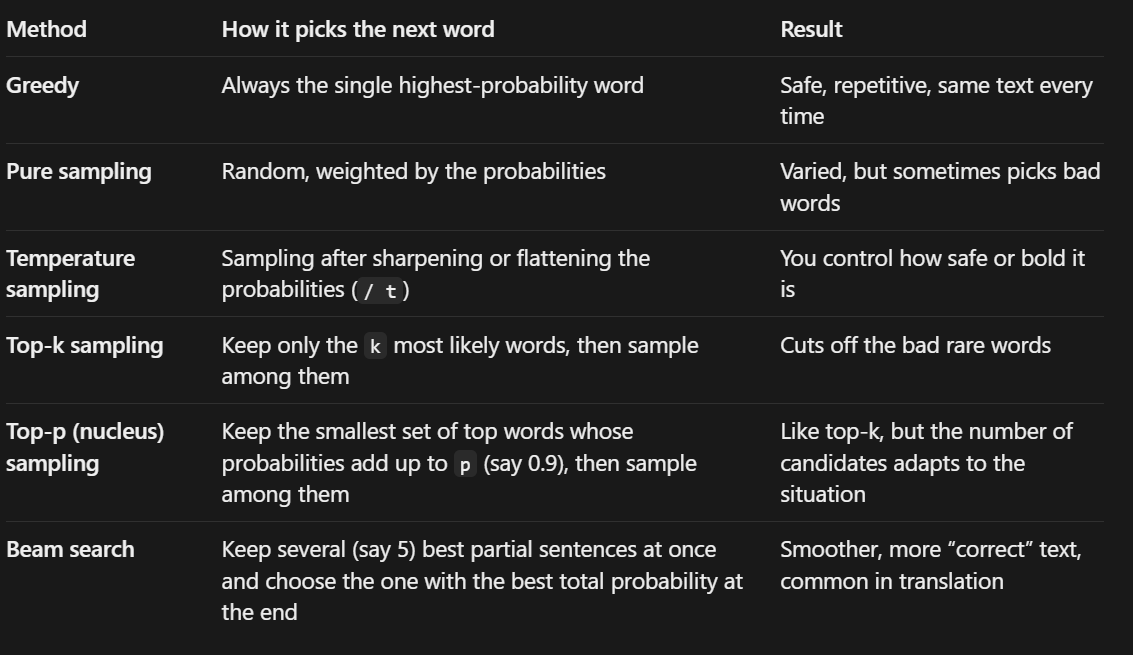

### 2.5 Generate text (always the most likely word)

Give the model 4 starting words. It predicts the next word, we add it, slide the window, and repeat. Taking the top word every time always gives the same text.

In [15]:
def generate_greedy(model, seed, n_words=10):
    words = clean(seed).split()
    ctx = [word2idx.get(w, 0) for w in words][-SEQ_LEN:]
    for _ in range(n_words):
        probs = model.predict(np.array([ctx]), verbose=0)[0]
        nxt = int(np.argmax(probs))
        words.append(idx2word.get(nxt, "<unk>"))
        ctx = ctx[1:] + [nxt]
    return " ".join(words)

print(generate_greedy(rnn, "twinkle twinkle little star"))

twinkle twinkle little star how i wonder what you are up above the world


### 2.6 Temperature: controlled randomness

Instead of always taking the top word, we **sample** from the probabilities. Temperature controls how bold the sampling is:

- **low** (close to 0): safe and repetitive, almost always the top word,
- **high** (above 1): varied but with more mistakes.

The model's probabilities are turned into `log(p) / t`, then back into probabilities with softmax.

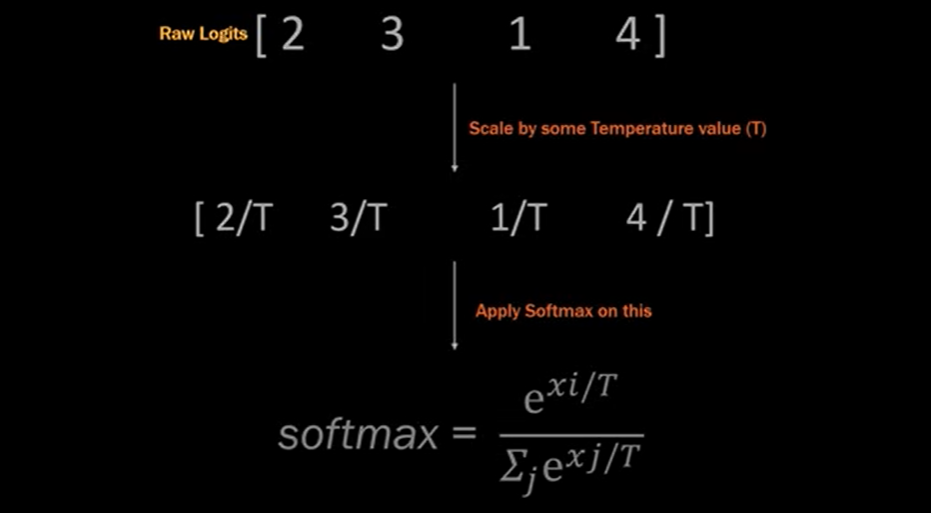

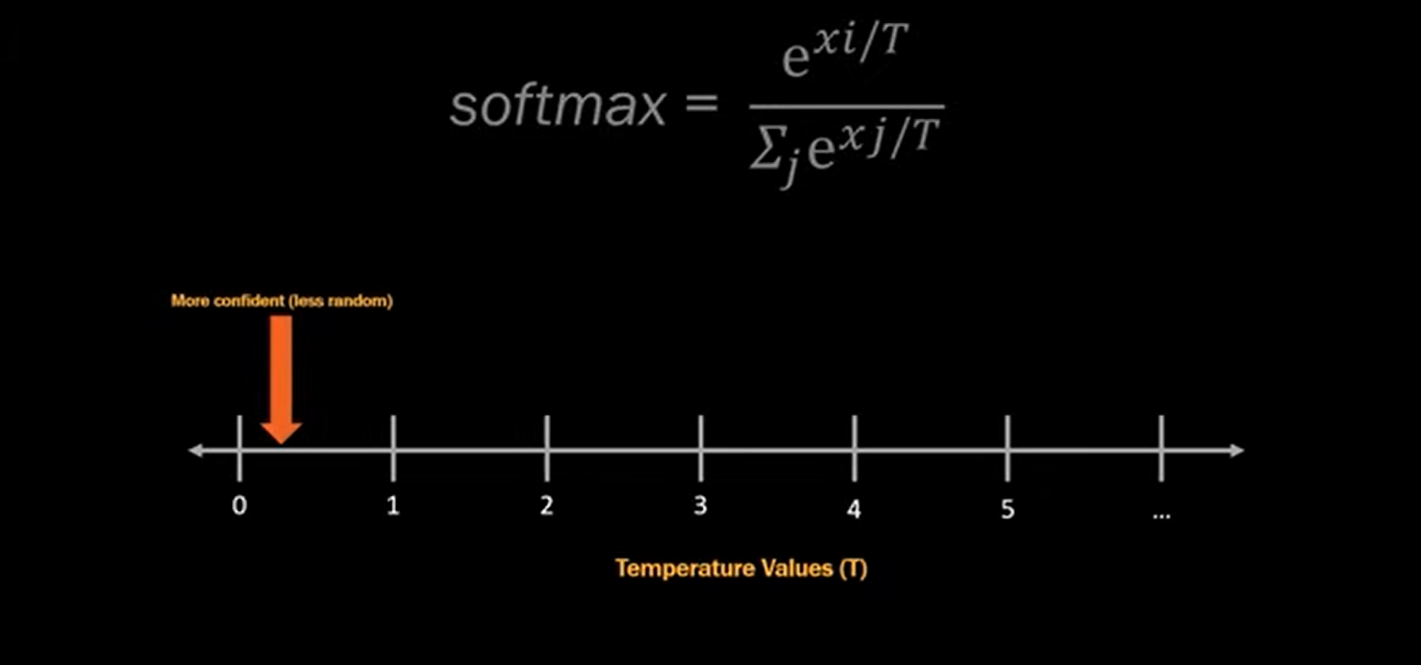

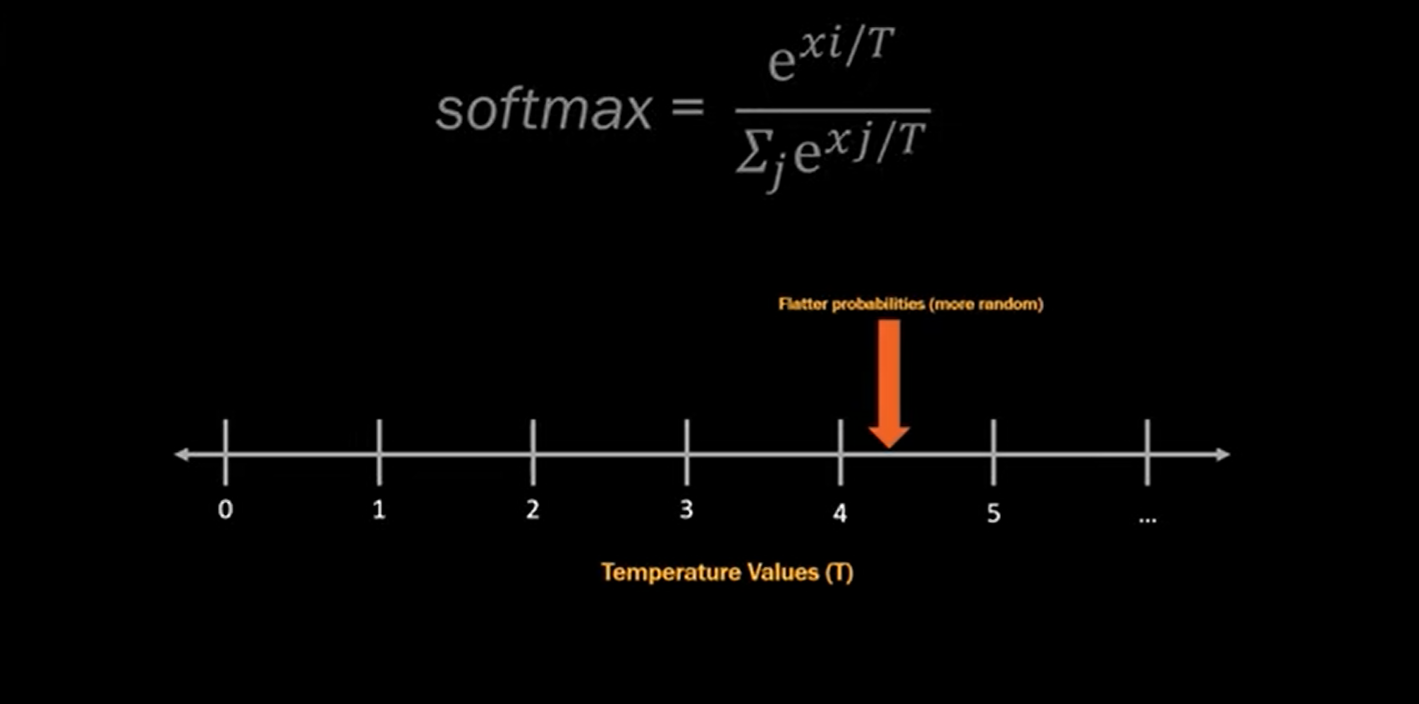

In [16]:
def sample_with_temperature(probs, t):
    if t <= 0:
        return int(np.argmax(probs))
    logits = np.log(probs + 1e-9) / t
    e = np.exp(logits - logits.max())
    e = e / e.sum()
    return int(np.random.choice(len(e), p=e))

def generate(model, seed, n_words=10, t=0.0):
    words = clean(seed).split()
    ctx = [word2idx.get(w, 0) for w in words][-SEQ_LEN:]
    for _ in range(n_words):
        probs = model.predict(np.array([ctx]), verbose=0)[0]
        nxt = sample_with_temperature(probs, t)
        words.append(idx2word.get(nxt, "<unk>"))
        ctx = ctx[1:] + [nxt]
    return " ".join(words)

for name, mdl in [("SimpleRNN", rnn), ("LSTM", lstm)]:
    for seed in ["twinkle twinkle little star", "the little cat sat"]:
        for t in [0, 0.7, 1.5]:
            print(f"{name} | t={t} | {generate(mdl, seed, 10, t)}")

SimpleRNN | t=0 | twinkle twinkle little star how i wonder what you are up above the world


SimpleRNN | t=0.7 | twinkle twinkle little star how i wonder what you are up above the world


SimpleRNN | t=1.5 | twinkle twinkle little star how i wonder what you are humpty dumpty sat had


SimpleRNN | t=0 | the little cat sat lives on the and mary above the little lamb high


SimpleRNN | t=0.7 | the little cat sat lives was the and mary for the little was who


SimpleRNN | t=1.5 | the little cat sat lives on the and mary sport the itsy was high


... (2 outputs left out)

LSTM | t=1.5 | twinkle twinkle little star how i wonder what you above humpty dumpty sat on


LSTM | t=0 | the little cat sat lives down the and mary all the a little couldnt


LSTM | t=0.7 | the little cat sat lives down and and mary dock soul little was and


LSTM | t=1.5 | the little cat sat lives down and and mary dock a a great all


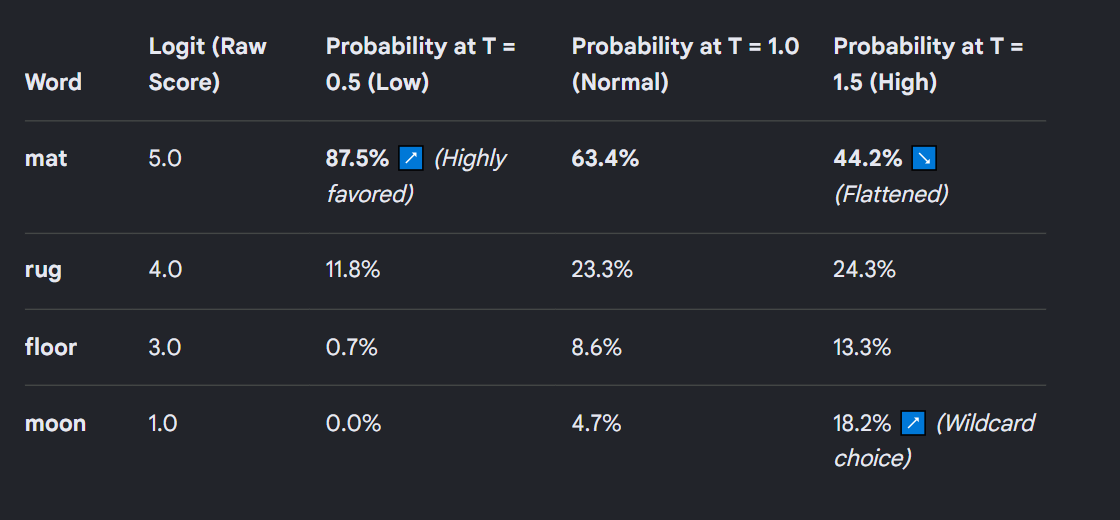

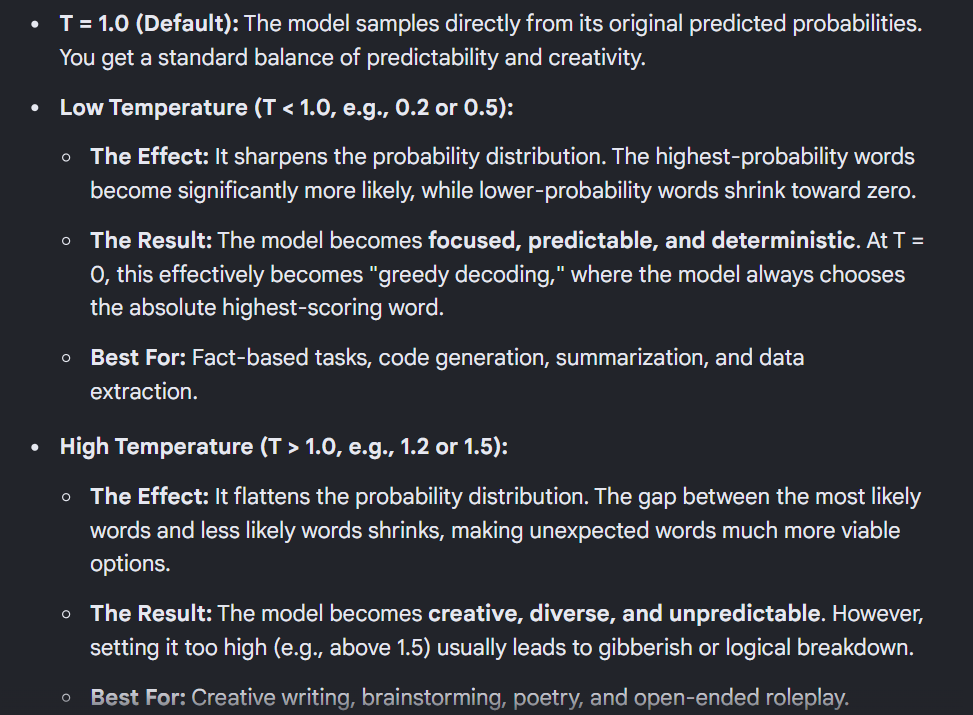

### 2.7 Overfitting experiment

We change **one thing at a time** and look at the train accuracy, the test accuracy and the test loss:

- a smaller LSTM (64 units instead of 256),
- fewer epochs (20 instead of 50),
- a **random** split instead of a split by position.

The random split gives a higher test accuracy, but the model is no better. The test set now contains near-copies of training windows, so this is a leak, not learning.

In [17]:
def experiment(kind, units, epochs, random_split):
    if random_split:
        perm = np.random.permutation(len(X))
        Xs, ys = X[perm], y[perm]
    else:
        Xs, ys = X, y
    Xtr, Xte, ytr, yte = split_by_position(Xs, ys, 0.8)
    model = build_model(kind, units)
    h = model.fit(Xtr, ytr, epochs=epochs, batch_size=32, validation_data=(Xte, yte), verbose=0)
    return {"model": kind, "units": units, "epochs": epochs,
            "split": "random" if random_split else "position",
            "train_acc": round(h.history["accuracy"][-1], 3),
            "test_acc": round(h.history["val_accuracy"][-1], 3),
            "test_loss": round(h.history["val_loss"][-1], 2)}

runs = [("lstm", 256, 50, False), ("lstm", 64, 50, False), ("lstm", 256, 20, False), ("lstm", 256, 50, True)]
experiments = pd.DataFrame([experiment(*r) for r in runs])
print(experiments)

  model  units  epochs     split  train_acc  test_acc  test_loss
0  lstm    256      50  position      0.971     0.000      13.75
1  lstm     64      50  position      0.953     0.023       8.04
2  lstm    256      20  position      0.793     0.023      11.53
3  lstm    256      50    random      0.956     0.047      10.00


# Part 03 (Bonus): Pre-trained Transformer

**Big idea:** a Transformer such as GPT-2 was already trained on huge amounts of text, so it already knows English. We only use it. This part needs internet, so run it in Colab.

### 3.1 Load DistilGPT-2 and generate text

We load a small pre-trained model and give it the start of a sentence. It continues the text one token at a time.

In [18]:
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained("distilgpt2")
    gpt = AutoModelForCausalLM.from_pretrained("distilgpt2")
    gpt.eval()
    GPT_OK = True
except Exception as e:
    GPT_OK = False
    print("Could not load the model:", type(e).__name__, "- run this in Colab with internet.")

def gpt_generate(prompt, temperature=1.0, top_k=50, max_new_tokens=30):
    inputs = tok(prompt, return_tensors="pt")
    with torch.no_grad():
        out = gpt.generate(**inputs, do_sample=True, temperature=temperature, top_k=top_k,
                           max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id)
    return tok.decode(out[0], skip_special_tokens=True)

if GPT_OK:
    print(gpt_generate("Twinkle twinkle little"))

Could not load the model: ModuleNotFoundError - run this in Colab with internet.


#TOP P

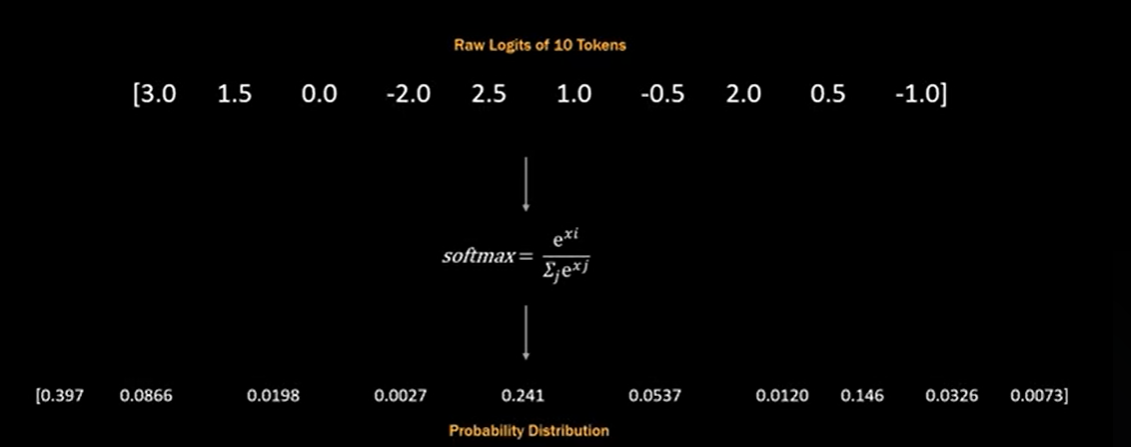

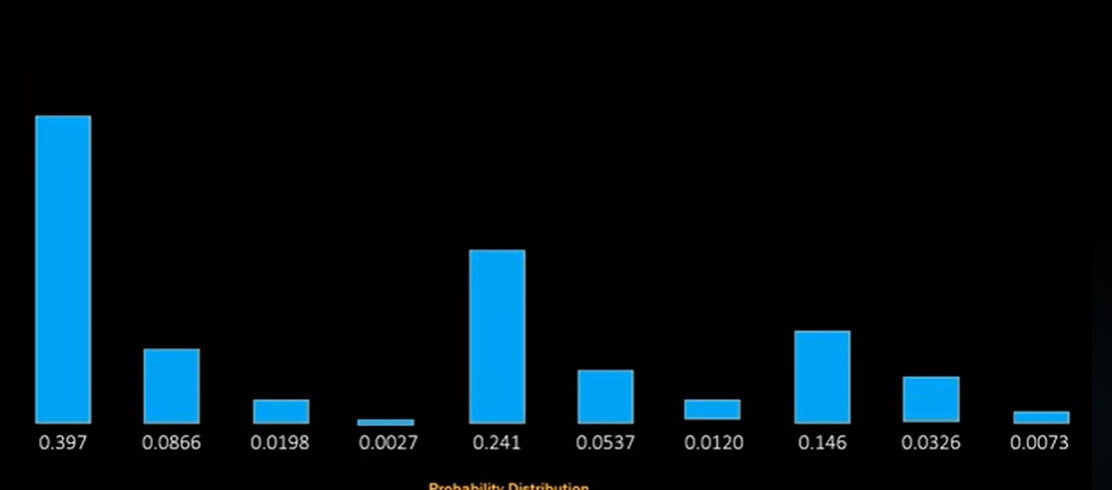

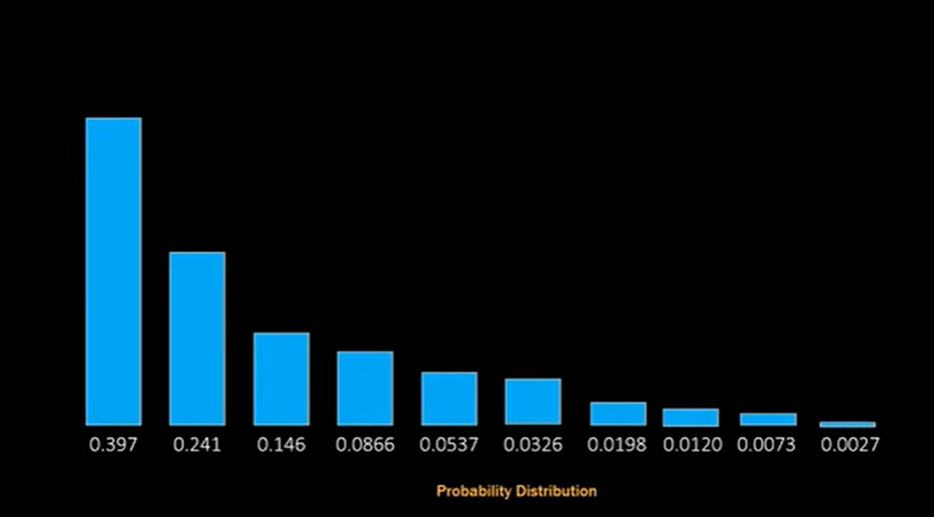

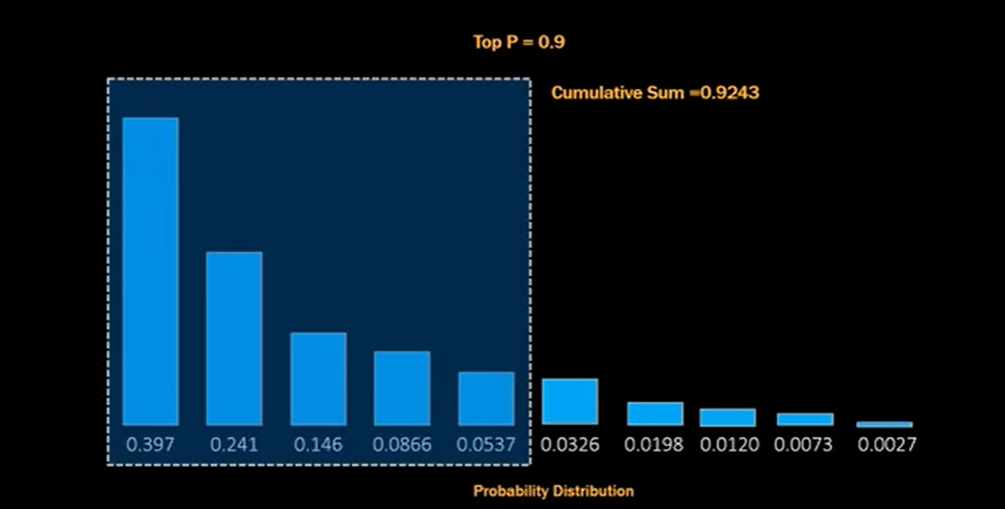

### 3.2 Temperature and top-k with a real model

`temperature` works the same way as before. `top_k` keeps only the k most likely words at each step: a small k is safe, a large k allows more variety.`top_k example: top_k = 5 means take 5 tokens from probability values with highest probabilty `

##top_k can be used in combination with temperature to control randomness

In [19]:
if GPT_OK:
    for t in [0.3, 1.0, 1.8]:
        for _ in range(3):
            print(f"temperature={t}:", gpt_generate("Twinkle twinkle little", temperature=t))
    for k in [5, 100]:
        print(f"top_k={k}:", gpt_generate("Twinkle twinkle little", temperature=1.0, top_k=k))

# Student Tasks: Build Something

Now you create your own language-model tools. Use the functions built above (`preprocess`, `count_ngrams`, `next_probs`, `generate`, `prob_addk`, `perplexity`, `make_windows`, `split_by_position`, `build_model`, `sample_with_temperature`) and write all **new** code yourself in the empty cells. Add a text cell after each task for your explanations.

Submit the notebook with every cell run and all outputs visible. Explanations must be in your own words.

## Task 1: A next-word suggester from your own text (n-grams)

**Goal:** Build a small word-suggestion tool, like the one on a phone keyboard, from text you write yourself.

**What to build**

1. Write at least 20 sentences of your own (for example about your university, hostel life or cricket). Do not copy text from the internet.
2. Preprocess them and keep the **last 20% of the sentences as test data**.
3. Build unigram, bigram and trigram models on the training part.
4. Choose the best smoothing value k by testing several values on the held-out sentences.
5. Write `suggest(text, how_many=3)` that returns the most likely next words with their probabilities. It should use the trigram when the last two words were seen in training, **fall back** to the bigram when they were not, and to the unigram as a last resort.

**What to submit**

- Output of `suggest` for at least 5 inputs, including one input with a word the model has never seen.
- A table of unigram, bigram and trigram perplexity on your held-out sentences for your best k.
- A short paragraph: how often did the fallback happen, and what does that say about your data size?

In [20]:
# Task 1: next-word suggester built from my own sentences (n-grams with add-k smoothing)
my_text = """I go to the university every morning.
The university library is quiet in the morning.
My friends and I play cricket after class.
We play cricket on the ground near the hostel.
The hostel food is not very good.
I eat lunch with my friends in the cafeteria.
The teacher gave us a hard assignment today.
I study in the library every evening.
Our team won the cricket match yesterday.
The captain scored fifty runs in the match.
I like to drink tea after class.
My roommate likes to play cricket in the evening.
The bus to the university is always late.
We have an exam in the morning.
I study with my friends in the hostel.
The cafeteria serves tea and biscuits in the evening.
The teacher asked me a hard question in class.
I go to the library after lunch.
Our captain likes to play cricket with the team.
The hostel is quiet in the evening.
My friends and I drink tea in the cafeteria.
The match starts in the evening at the ground.
I have a class in the morning every day.
The teacher is happy with our team.
We go to the hostel after the match."""

my_sents_raw = [s.strip() for s in my_text.split("\n") if s.strip()]
cut_s = int(0.8 * len(my_sents_raw))              # last 20% of the sentences are test data
train_text = " ".join(my_sents_raw[:cut_s])
test_text  = " ".join(my_sents_raw[cut_s:])
print("Sentences:", len(my_sents_raw), "| train:", cut_s, "| test:", len(my_sents_raw) - cut_s)

# --- unigram, bigram, trigram models on the training part
uni_m = count_ngrams(preprocess(train_text, 1), 1)
bi_m  = count_ngrams(preprocess(train_text, 2), 2)
tri_m = count_ngrams(preprocess(train_text, 3), 3)
ng_models = {1: uni_m, 2: bi_m, 3: tri_m}

vocab_m = {w for s in preprocess(train_text, 1) for w in s} | {"<unk>"}   # includes </s>
V_m = len(vocab_m)
print("Vocabulary (train words + </s> + <unk>):", V_m)

def map_unk(sent, vocab):
    """Replace words the model never saw by <unk> (keep <s> padding)."""
    return [w if (w in vocab or w == "<s>") else "<unk>" for w in sent]

def prob_addk(counts, context, word, k, V):
    """Add-k smoothed P(word | context)."""
    c = counts.get(tuple(context), Counter())
    return (c[word] + k) / (sum(c.values()) + k * V)

def perplexity(counts, n, sents, k, V, vocab):
    """Perplexity of an n-gram model (add-k) on a list of padded sentences."""
    logs = []
    for s in sents:
        s = map_unk(s, vocab)
        for i in range(n - 1, len(s)):
            logs.append(math.log(prob_addk(counts, s[i - n + 1:i], s[i], k, V)))
    return math.exp(-sum(logs) / len(logs))

# --- choose k on the held-out sentences
k_grid = [0.01, 0.05, 0.1, 0.3, 0.5, 1.0]
rows = []
for k in k_grid:
    rows.append({"k": k, **{name: round(perplexity(ng_models[n], n, preprocess(test_text, n), k, V_m, vocab_m), 2)
                             for n, name in [(1, "unigram"), (2, "bigram"), (3, "trigram")]}})
k_table = pd.DataFrame(rows).set_index("k")
print(k_table)
# one k for all three models: the one with the lowest mean log-perplexity
best_k = min(k_grid, key=lambda k: np.mean(np.log(k_table.loc[k].values)))
print("\nBest k:", best_k)

final = pd.DataFrame({"model": ["unigram", "bigram", "trigram"],
                      "test perplexity": [k_table.loc[best_k, m] for m in ["unigram", "bigram", "trigram"]]})
print(final.to_string(index=False))


Sentences: 25 | train: 20 | test: 5
Vocabulary (train words + </s> + <unk>): 67
      unigram  bigram  trigram
k                             
0.01    56.56   26.16    39.04
0.05    49.52   21.54    34.30
0.10    46.92   22.39    35.28
0.30    43.59   27.29    40.15
0.50    42.55   31.09    43.55
1.00    41.99   37.53    48.78

Best k: 0.05
  model  test perplexity
unigram            49.52
 bigram            21.54
trigram            34.30


In [21]:
# --- suggest(): trigram -> bigram -> unigram back-off
def suggest(text, how_many=3, verbose=True):
    words = [w.strip("'") for w in re.sub(r"[^a-z'\s]", "", text.lower()).split()]
    words = [w for w in words if w]
    hist = ["<s>", "<s>"] + words                  # typing at sentence start -> <s> context
    if tuple(hist[-2:]) in tri_m:
        level, counts = "trigram", tri_m[tuple(hist[-2:])]
    elif tuple(hist[-1:]) in bi_m:
        level, counts = "bigram", bi_m[tuple(hist[-1:])]
    else:
        level, counts = "unigram", uni_m[()]
    total = sum(counts.values())
    out = [(("<end>" if w == "</s>" else w), round(c / total, 3)) for w, c in counts.most_common(how_many)]
    if verbose:
        print(f"{text!r:32} [{level}] ->", out)
    return level, out

for text in ["I play", "the hostel", "my friends and", "we go to the", "the teacher likes", "i study in the quantum"]:
    suggest(text)

# --- how often did the fallback happen on the held-out sentences?
levels = Counter()
for s in preprocess(test_text, 3):
    s = map_unk(s, vocab_m)
    for i in range(2, len(s) - 1):               # predict every real word of the sentence
        levels[suggest(" ".join(w for w in s[2:i]), verbose=False)[0]] += 1
tot = sum(levels.values())
print("\nSuggestion level used at", tot, "positions of the held-out sentences:")
for lv in ["trigram", "bigram", "unigram"]:
    print(f"  {lv:8}: {levels[lv]:3d}  ({levels[lv] / tot:.0%})")
test_words = [w for s in preprocess(test_text, 1) for w in s if w != "</s>"]
print("Held-out words never seen in training:", sorted({w for w in test_words if w not in vocab_m}))


'I play'                         [trigram] -> [('cricket', 1.0)]
'the hostel'                     [trigram] -> [('<end>', 0.5), ('food', 0.25), ('is', 0.25)]
'my friends and'                 [trigram] -> [('i', 1.0)]
'we go to the'                   [trigram] -> [('university', 0.667), ('library', 0.333)]
'the teacher likes'              [bigram] -> [('to', 1.0)]
'i study in the quantum'         [unigram] -> [('the', 0.135), ('<end>', 0.112), ('in', 0.056)]

Suggestion level used at 42 positions of the held-out sentences:
  trigram :  24  (57%)
  bigram  :  15  (36%)
  unigram :   3  (7%)
Held-out words never seen in training: ['at', 'day', 'happy', 'starts']


**Task 1: explanation**

I wrote 25 sentences about university, hostel life and cricket, used the first 20 for training and the last 5 as test data, and built unigram, bigram and trigram models with add-k smoothing. The best k on the held-out sentences was **0.05**. At that k the test perplexities are unigram 49.5, bigram 21.5 and trigram 34.3. The trigram is *worse* than the bigram because 20 sentences are far too little text for two-word contexts: most trigram contexts were seen only once or never, so the model is very confident about a few continuations and badly wrong on new ones. (Note: k was chosen on the same 5 sentences used for the table, so these numbers are slightly optimistic. With more data I would use a separate validation set.)

`suggest()` uses the trigram when the last two words were seen, then the bigram, then the unigram. Over the 42 word positions of the held-out sentences the **trigram was used 57% of the time, the bigram 36% and the unigram 7%**, so for 43% of the predictions the model had to fall back. Four held-out words (*at, day, happy, starts*) never appeared in training. This shows the data is too small: even in a very repetitive text (the same few topics), nearly half of all two-word contexts are new. The input `i study in the quantum` (unseen word) correctly fell back to the unigram.

## Task 2: A neural language model on your own text

**Goal:** Train recurrent models on a larger text and study what affects their quality.

**What to build**

1. Make a text file of at least 300 words (you can combine your own writing from Task 1 with `nursery_rhymes.txt`).
2. Create the training windows for window sizes of 3 and 5 words, and split them by position.
3. Train a SimpleRNN and an LSTM for **each** window size (four models).
4. Convert each model's test loss to a perplexity with `exp(test_loss)`.
5. Compute the baseline that always predicts the most common word.

**What to submit**

- One table with the four models: window size, parameters, train accuracy, test accuracy, test perplexity, and the baseline.
- Loss curves for the best model.
- A hypothesis written **before** training (does a longer window help? does the LSTM beat the SimpleRNN?), and a paragraph saying whether the results agreed.
- Two or three sentences explaining the gap between train and test accuracy.

In [22]:
# Task 2, step 1: build a text file of 300+ words = nursery rhymes + my own sentences (interleaved)
stanzas = [s.strip() for s in open("nursery_rhymes.txt", encoding="utf-8").read().strip().split("\n\n")]
mine_chunks = [list(c) for c in np.array_split(my_sents_raw, len(stanzas))]
blocks = []
for st, chunk in zip(stanzas, mine_chunks):
    blocks += [st, " ".join(chunk)]
combined = "\n\n".join(b for b in blocks if b)
with open("combined_corpus.txt", "w", encoding="utf-8") as f:
    f.write(combined)

c_tokens = clean(combined).split()
c_w2i = {w: i + 1 for i, w in enumerate(sorted(set(c_tokens)))}     # 0 = unknown
c_i2w = {i: w for w, i in c_w2i.items()}
C_VOCAB = len(c_w2i) + 1
c_ids = [c_w2i[w] for w in c_tokens]
print("Words in combined_corpus.txt:", len(c_tokens), "| vocabulary:", C_VOCAB)
assert len(c_tokens) >= 300


Words in combined_corpus.txt: 633 | vocabulary: 257


**Hypothesis (written before training the four models)**

1. **Window size:** a longer window (5 words) gives the model more context, so I expect it to lower the *test* perplexity a little compared with a window of 3. On a corpus of only ~630 words I expect the gain to be small.
2. **Model type:** the LSTM has gates that decide what to remember, so I expect it to beat the SimpleRNN on the test set.
3. **Overall:** with so little text I expect every model to fit the training windows almost perfectly (train accuracy near 100%) but to do badly on the test windows, because the test part contains word combinations never seen in training.


In [23]:
def build_model_w(kind, seq_len, vocab, units=256):
    recurrent = layers.SimpleRNN(units) if kind == "rnn" else layers.LSTM(units)
    m = models.Sequential([layers.Input(shape=(seq_len,)), layers.Embedding(vocab, 128),
                           recurrent, layers.Dense(vocab, activation="softmax")])
    m.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return m

results, trained, histories = [], {}, {}
for L in [3, 5]:
    Xw, yw = make_windows(c_ids, L)
    Xtr, Xte, ytr, yte = split_by_position(Xw, yw, 0.8)
    base_word = Counter(ytr.tolist()).most_common(1)[0][0]
    base_acc = float(np.mean(yte == base_word))
    for kind, name in [("rnn", "SimpleRNN"), ("lstm", "LSTM")]:
        tf.keras.utils.set_random_seed(7)
        m = build_model_w(kind, L, C_VOCAB)
        h = m.fit(Xtr, ytr, epochs=EPOCHS, batch_size=32, validation_data=(Xte, yte), verbose=0)
        vl = h.history["val_loss"]
        results.append({"window": L, "model": name, "parameters": m.count_params(),
                        "train_acc": round(h.history["accuracy"][-1], 3),
                        "test_acc": round(h.history["val_accuracy"][-1], 3),
                        "test_perplexity": round(math.exp(vl[-1]), 1),
                        "best_epoch": int(np.argmin(vl)) + 1,
                        "min_test_perplexity": round(math.exp(min(vl)), 1),
                        "baseline_acc": round(base_acc, 3)})
        trained[(L, name)], histories[(L, name)] = m, h
task2 = pd.DataFrame(results)
print("Train windows:", len(Xtr), "| test windows:", len(Xte), "(window 5)")
print(task2.to_string(index=False))


Train windows: 502 | test windows: 126 (window 5)
 window     model  parameters  train_acc  test_acc  test_perplexity  best_epoch  min_test_perplexity  baseline_acc
      3 SimpleRNN      197505      0.929     0.056          10865.6           1                246.9         0.095
      3      LSTM      493185      0.925     0.032         173086.3           2                245.1         0.095
      5 SimpleRNN      197505      0.988     0.032          15791.5           1                226.8         0.095
      5      LSTM      493185      0.988     0.032         388079.7           1                250.2         0.095


Best model (lowest final test perplexity): (3, 'SimpleRNN')


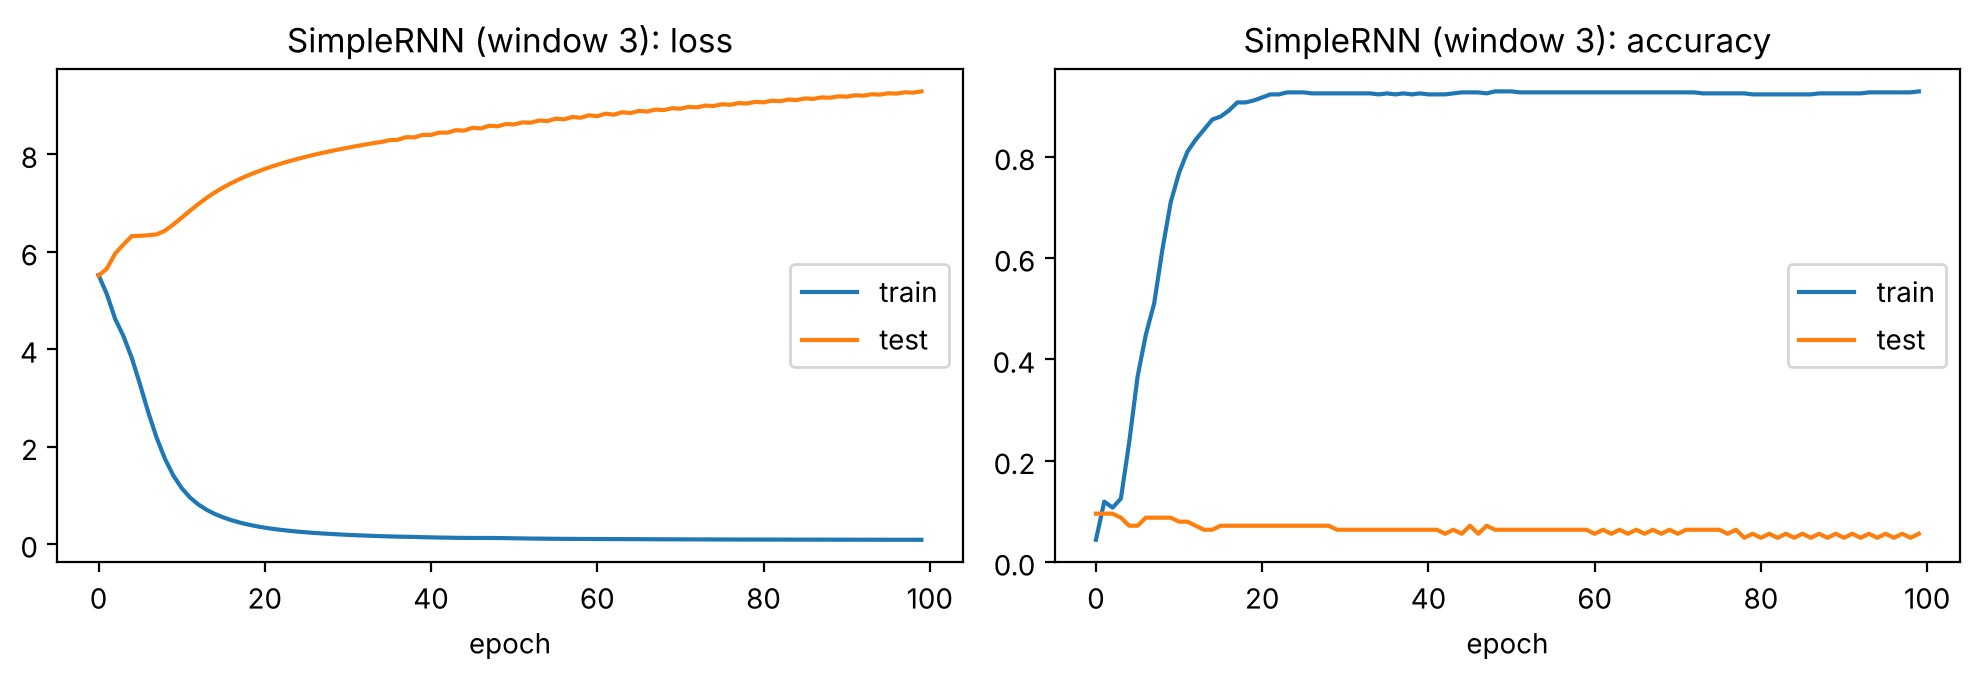

In [24]:
best_key = min(trained, key=lambda k: math.exp(histories[k].history["val_loss"][-1]))
print("Best model (lowest final test perplexity):", best_key)
plot_history(histories[best_key], f"{best_key[1]} (window {best_key[0]})")
best_L, best_model = best_key[0], trained[best_key]


**Task 2: explanation**

*Did the results agree with the hypothesis?* **Mostly not.**

- **Window size:** a longer window did not help. With the final-epoch test perplexity, window 5 was worse than window 3 for both models (SimpleRNN 15,792 vs 10,866; LSTM 388,080 vs 173,086). With about 500 training windows, a 5-word input is even more unique than a 3-word input, so it is easier to memorise and does not generalise.
- **LSTM vs SimpleRNN:** the LSTM did not beat the SimpleRNN at the end of training. It has 2.5 times more parameters (493,185 vs 197,505) and overfits even harder (its test loss rises more). The *lowest* test perplexity during training (about 227 to 250, reached after only 1 or 2 epochs) is about equal for all four models, so there is no clear winner.
- **Overall:** this part of the hypothesis was right. Train accuracy is 93 to 99%, but test accuracy is only 3 to 6%, which is **below the baseline of 9.5%** (always predicting the most common word). None of the four models beat the trivial baseline on accuracy.

*Train/test gap.* The models have 200k to 500k weights but only about 500 training windows, so they simply memorise which word followed each window. The test part contains word combinations (and some words) that never occurred in training, and memorising does not help there. The test loss is lowest after 1 or 2 epochs and then grows as the model becomes more and more confident about wrong words, which is why the test perplexity at epoch 100 is in the thousands or more.

## Task 3: A text-writing tool using two models

**Goal:** Put an n-gram model and a neural model behind one function and compare how they write.

**What to build**

1. Write `write_text(seed, n_words, model_type, t)` that continues a seed with either your n-gram model or your best neural model (from Task 2). For the neural model use `sample_with_temperature`.
2. Write a short loop that takes five seeds and prints, side by side, the continuation from the n-gram model and from the neural model at three temperatures.
3. Add a simple guard: if the seed contains a word the model has never seen, print a warning instead of failing.

**What to submit**

- The side-by-side output for five seeds (use at least two seeds taken from your text and two you invent).
- A paragraph answering: which model copies the training text more, which produces new combinations, and what happens to quality as the temperature goes up? Use your own outputs as evidence.

In [25]:
# Task 3: one function, two kinds of model
def prep_clean(text, n):
    """Same as preprocess() but strips apostrophes like clean(), so n-gram and neural vocabularies match."""
    out = []
    for sent in re.split(r"[.!?]+", text):
        words = clean(sent).split()
        if words:
            out.append(["<s>"] * (n - 1) + words + ["</s>"])
    return out

# n-gram models trained on the SAME combined text as the neural models
ng = {n: count_ngrams(prep_clean(combined, n), n) for n in (1, 2, 3)}
known = set(c_w2i)

def ngram_next(history, t):
    """Trigram if the 2-word context was seen, else bigram, else unigram; temperature applied to the counts."""
    for n in (3, 2, 1):
        ctx = tuple(history[len(history) - (n - 1):]) if n > 1 else ()
        c = ng[n].get(ctx)
        if c:
            break
    words = list(c)
    counts = np.array([c[w] for w in words], dtype=float)
    if t <= 0:
        return words[int(np.argmax(counts))]
    p = counts ** (1.0 / t)            # same as p**(1/t) after re-normalising
    return words[np.random.choice(len(words), p=p / p.sum())]

def write_text(seed, n_words=10, model_type="ngram", t=1.0):
    words = clean(seed).split()
    unseen = [w for w in words if w not in known]
    if not words or unseen:                       # guard: warn instead of failing
        print(f"  WARNING: seed {seed!r} has words the model has never seen: {unseen}")
        return None
    out = list(words)
    if model_type == "ngram":
        hist = ["<s>", "<s>"] + words
        produced = 0
        while produced < n_words:
            w = ngram_next(hist, t)
            if w == "</s>":                        # sentence ended: start a new one
                hist += ["<s>", "<s>"]
                continue
            hist.append(w); out.append(w); produced += 1
    else:
        ids_ = [c_w2i[w] for w in words]
        ctx = ([0] * best_L + ids_)[-best_L:]      # pad on the left if the seed is shorter than the window
        for _ in range(n_words):
            probs = best_model(np.array([ctx]), training=False).numpy()[0]
            nxt = sample_with_temperature(probs, t)
            out.append(c_i2w.get(nxt, "<unk>"))
            ctx = ctx[1:] + [nxt]
    return " ".join(out)

seeds = ["twinkle twinkle little star",      # from my text (nursery rhymes)
         "my friends and i",                  # from my text (my sentences)
         "the cat likes tea",                 # invented, all words known
         "my teacher likes cricket",          # invented, all words known
         "the quantum computer"]              # contains unseen words -> guard
temps = [0.3, 1.0, 1.5]

random.seed(7); np.random.seed(7)
for seed in seeds:
    print("=" * 100)
    print("SEED:", seed)
    for t in temps:
        a = write_text(seed, 10, "ngram", t)
        b = write_text(seed, 10, "neural", t)
        if a is not None:
            print(f"  t={t:<3} | n-gram : {a}")
            print(f"        | neural : {b}")


SEED: twinkle twinkle little star


  t=0.3 | n-gram : twinkle twinkle little star how i wonder what you are i go to the
        | neural : twinkle twinkle little star how i wonder what you are i go to the


  t=1.0 | n-gram : twinkle twinkle little star how i wonder what you are little miss muffet sat
        | neural : twinkle twinkle little star how i wonder what you are up above the world
  t=1.5 | n-gram : twinkle twinkle little star how i wonder what you are merrily merrily merrily life
        | neural : twinkle twinkle little star how i any us the sir like water three down
SEED: my friends and i


  t=0.3 | n-gram : my friends and i play cricket after class the teacher is happy with our
        | neural : my friends and i play cricket after class we play cricket on the ground


  t=1.0 | n-gram : my friends and i drink tea after class little children want to play cricket
        | neural : my friends and i drink tea in the cafeteria baa baa black sheep have


  t=1.5 | n-gram : my friends and i drink tea in the library every evening along came a
        | neural : my friends and i drink tea in the cafeteria not baa go quiet captain
SEED: the cat likes tea


  t=0.3 | n-gram : the cat likes tea and biscuits in the morning the hostel the teacher gave
        | neural : the cat likes tea fiddle cricket cafeteria jumped we go moon exam library dog


  t=1.0 | n-gram : the cat likes tea after class jack fell down and broke his crown and
        | neural : the cat likes tea fiddle cricket cafeteria jumped we go moon lamb university dog
  t=1.5 | n-gram : the cat likes tea after class london bridge is falling down falling down our
        | neural : the cat likes tea fiddle cricket cafeteria jumped pail go friends the university drink
SEED: my teacher likes cricket


  t=0.3 | n-gram : my teacher likes cricket on the ground near the hostel the teacher is happy
        | neural : my teacher likes cricket a cricket team put the cricket again yesterday team and


  t=1.0 | n-gram : my teacher likes cricket match yesterday they all ran after the farmers wife who
        | neural : my teacher likes cricket a cricket team put the cricket the yesterday the morning
  t=1.5 | n-gram : my teacher likes cricket after class all the rain and the dish ran away
        | neural : my teacher likes cricket a cricket in the evening hickory diddle diddle the cat
SEED: the quantum computer


**Task 3: explanation**

*Which model copies more?* The **neural model** (the best Task 2 model: a window-3 SimpleRNN trained for 100 epochs) copies the most. From the seed `twinkle twinkle little star` it reproduced `how i wonder what you are` word for word at t=0.3 and t=1.0, and for several seeds its output at t=0.3 and t=1.0 was **identical**, because after overfitting its probabilities are almost 100% on one word. The n-gram model also copies lines it has seen (same rhyme line at t=0.3), but it is less rigid.

*Which model makes new combinations?* The **n-gram model**: it jumps between contexts it has seen, e.g. `my friends and i drink tea after class little children want to play cricket` or `the cat likes tea after class jack fell down and broke his crown`. These sentences are new, but each 3-word piece comes from the text. For the invented seeds (`the cat likes tea`) the neural model produced word salad (`fiddle cricket cafeteria jumped we go moon`), because that 4-word context was never seen and the overfitted network has no good answer.

*Temperature.* At low temperature (0.3) the text is the most fluent and repetitive (it follows the most frequent continuation). At t=1.0 the n-gram text starts mixing topics, and at t=1.5 quality drops clearly: `merrily merrily merrily life`, `not baa go quiet captain`, `hickory diddle diddle the cat`. Higher temperature gives more variety but more mistakes. The guard works: the seed `the quantum computer` printed a warning instead of failing.

## Task 4: Final report: compare all models on the same text

**Goal:** Judge every model you built (and optionally DistilGPT-2) by one number, then explain honestly what the comparison does and does not show.

**What to build**

1. Pick one held-out text that **none** of the models trained on.
2. Compute the perplexity of the unigram, bigram and trigram models (with your best k), the SimpleRNN, and the LSTM on that text. Optionally add DistilGPT-2 (per-word perplexity).
3. Show the results as one table and one bar chart.
4. List at least three reasons why this comparison is **not completely fair** (think about vocabulary, how unknown words are handled, tokenizers, and the first words of each text) and say what you would change to make it fairer.

**What to submit**

- The table and the bar chart.
- A paragraph ranking the models and explaining the ranking.
- A paragraph on the unfairness points and one concrete improvement.
- A final conclusion of 4 to 5 sentences: when would you use counting models, recurrent models, and pre-trained Transformers?

Held-out words: 74 | unseen in training: 5 (7%)
Unseen words: ['lesson', 'read', 'slept', 'students', 'watched']


SimpleRNN: window=3, trained 1 epochs
SimpleRNN (100 epochs): window=3, trained 100 epochs
LSTM: window=3, trained 2 epochs
LSTM (100 epochs): window=3, trained 100 epochs

Words scored in the fair column: 64 of 74
                 model  perplexity (naive)  perplexity (fair: same known target words)
               Unigram               112.5                                       102.9
                Bigram                62.7                                        53.8
               Trigram               113.8                                        99.0
             SimpleRNN               190.0                                       181.3
                  LSTM               128.2                                       109.2
SimpleRNN (100 epochs)              3718.4                                      2489.1
     LSTM (100 epochs)              1964.9                                      1409.8


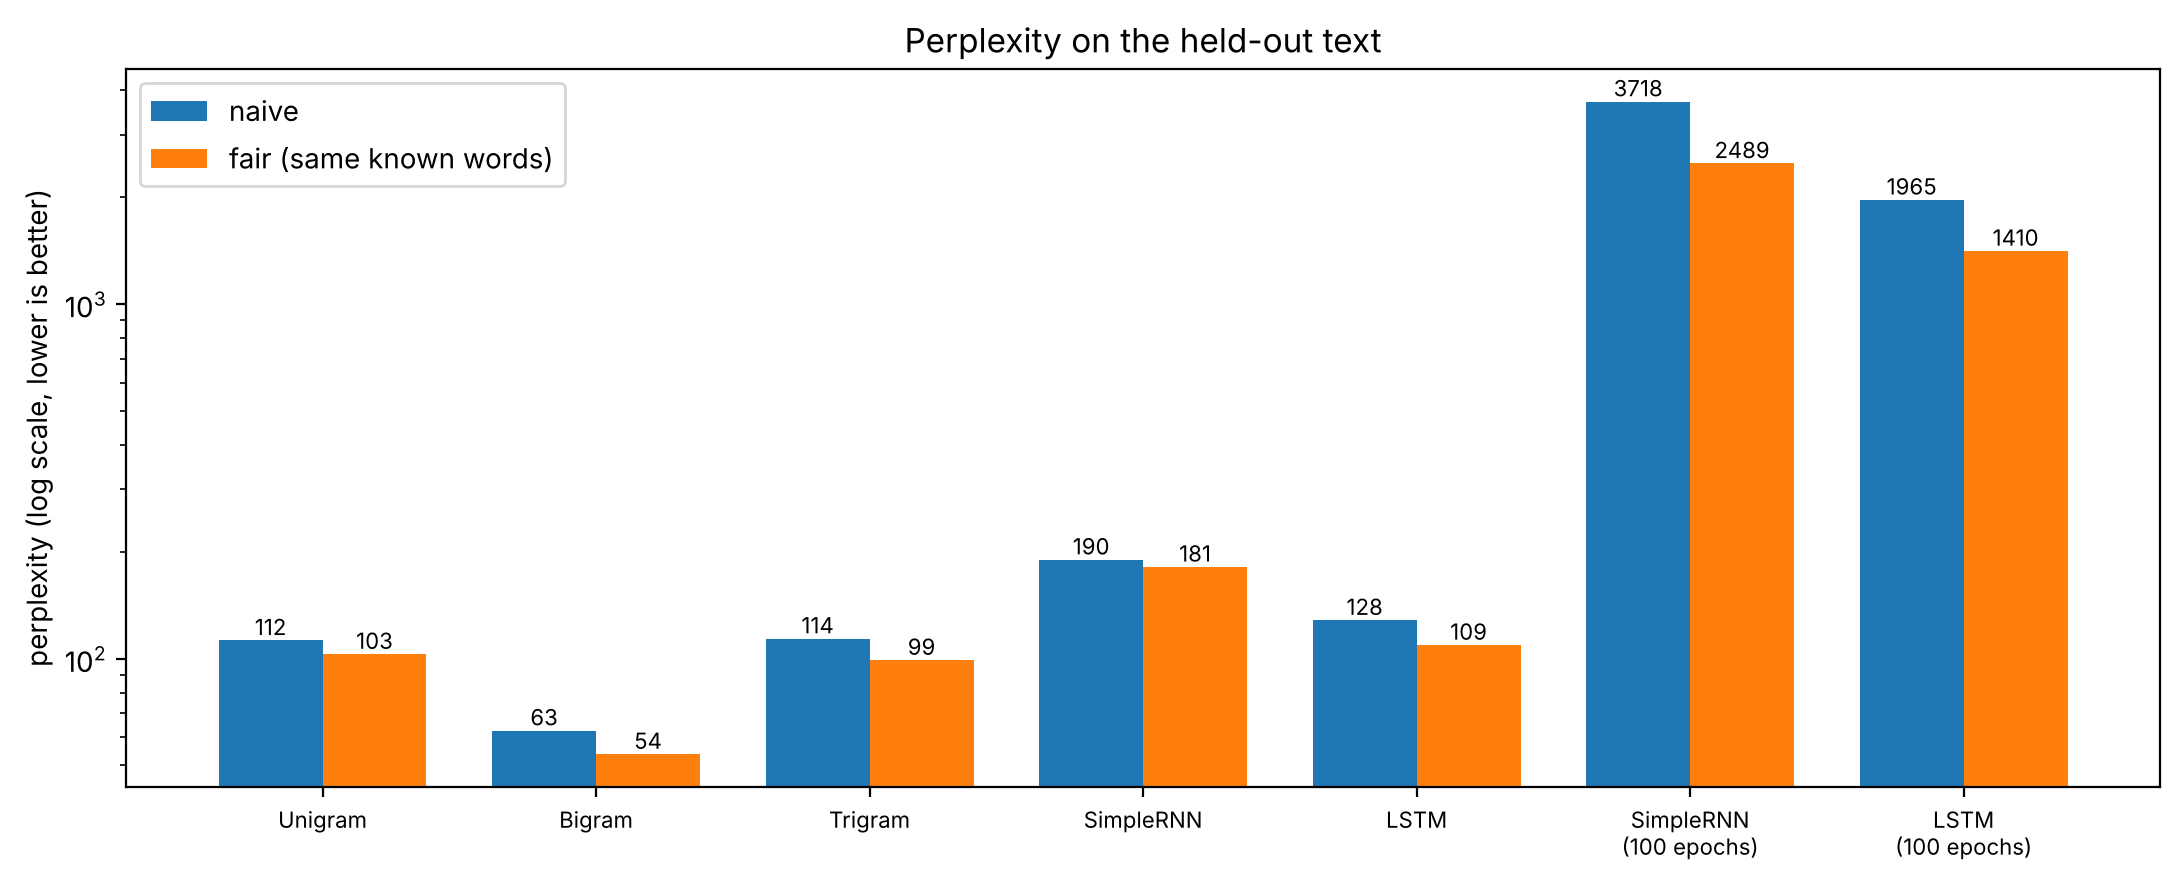

In [26]:
# Task 4: one held-out text, five models
held_text = """The sun came out and the children went to play. Our team won the match at the university ground.
I like to eat lunch with my friends. The little cat ran up the hill. Rain fell on the old bridge in the morning.
The teacher asked the students to read the lesson again. We sat on the wall and watched the cricket match.
The dog and the cat slept in the sun all day."""
held_tokens = clean(held_text).split()
held_ids = [c_w2i.get(w, 0) for w in held_tokens]            # unseen words -> 0
oov = sorted({w for w in held_tokens if w not in c_w2i})
print("Held-out words:", len(held_tokens), "| unseen in training:", len(oov), f"({len(oov) / len(held_tokens):.0%})")
print("Unseen words:", oov)

MAXL = 5   # all models are scored on the same target words: positions 5, 6, 7, ... of the held-out text

# ---- n-gram models (trained on all of the combined text), add-k with the best k from Task 1
vocab_c = set(c_w2i) | {"</s>", "<unk>"}
V_c = len(vocab_c)

def ngram_scores(n):
    """(position, target_is_known, log-prob) for every real word of the held-out text."""
    rows, pos = [], 0
    for s in prep_clean(held_text, n):
        s = map_unk(s, vocab_c)
        for i in range(n - 1, len(s) - 1):                    # real words only, not </s>
            lp = math.log(prob_addk(ng[n], s[i - n + 1:i], s[i], best_k, V_c))
            rows.append((pos, s[i] != "<unk>", lp)); pos += 1
    return rows

# naive: each model in its own natural setting (n-gram also predicts </s> and <unk>)
naive, fair = {}, {}
for n, name in [(1, "Unigram"), (2, "Bigram"), (3, "Trigram")]:
    naive[name] = perplexity(ng[n], n, prep_clean(held_text, n), best_k, V_c, vocab_c)
    sc = [lp for pos, known_, lp in ngram_scores(n) if pos >= MAXL and known_]
    fair[name] = math.exp(-np.mean(sc))

# ---- neural models: retrain the best window of each kind on ALL combined text, stopping where test loss was lowest
def neural_logps(model, L):
    Xh, yh = make_windows(held_ids, L)
    p = model(Xh, training=False).numpy()
    return np.log(p[np.arange(len(yh)), yh] + 1e-12), yh, np.arange(L, len(held_ids))

neural_info = []
for kind, name in [("rnn", "SimpleRNN"), ("lstm", "LSTM")]:
    cand = [k for k in trained if k[1] == name]
    L = min(cand, key=lambda k: math.exp(histories[k].history["val_loss"][-1]))[0]
    ep = int(np.argmin(histories[(L, name)].history["val_loss"])) + 1
    Xa, ya = make_windows(c_ids, L)
    # (a) stopped where the test loss of Task 2 was lowest, (b) trained for all 100 epochs like in Task 2
    for label, n_ep in [(name, ep), (name + " (100 epochs)", EPOCHS)]:
        tf.keras.utils.set_random_seed(7)
        m = build_model_w(kind, L, C_VOCAB)
        m.fit(Xa, ya, epochs=n_ep, batch_size=32, verbose=0)
        lp, yh, positions = neural_logps(m, L)
        naive[label] = math.exp(-lp.mean())                    # includes unseen targets (id 0)
        keep = (positions >= MAXL) & (yh != 0)
        fair[label] = math.exp(-lp[keep].mean())
        neural_info.append(f"{label}: window={L}, trained {n_ep} epochs")
print("\n".join(neural_info))

order = ["Unigram", "Bigram", "Trigram", "SimpleRNN", "LSTM", "SimpleRNN (100 epochs)", "LSTM (100 epochs)"]
final4 = pd.DataFrame({"model": order,
                       "perplexity (naive)": [round(naive[m], 1) for m in order],
                       "perplexity (fair: same known target words)": [round(fair[m], 1) for m in order]})
n_fair = int(sum(1 for pos, k_, _ in ngram_scores(1) if pos >= MAXL and k_))
print("\nWords scored in the fair column:", n_fair, "of", len(held_tokens))
print(final4.to_string(index=False))

x = np.arange(len(order)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 4.5))
b1 = ax.bar(x - w / 2, [naive[m] for m in order], w, label="naive")
b2 = ax.bar(x + w / 2, [fair[m] for m in order], w, label="fair (same known words)")
ax.set_xticks(x); ax.set_xticklabels([o.replace(' (', '\n(') for o in order], fontsize=8); ax.set_yscale("log")
ax.set_ylabel("perplexity (log scale, lower is better)"); ax.set_title("Perplexity on the held-out text")
for bars in (b1, b2):
    for r in bars:
        ax.annotate(f"{r.get_height():.0f}", (r.get_x() + r.get_width() / 2, r.get_height()),
                    ha="center", va="bottom", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()


**Task 4: explanation**

*Ranking (fair column, lower is better).* Bigram **53.8** < trigram 99.0 < unigram 102.9 < LSTM 109.2 < SimpleRNN 181.3 << LSTM trained 100 epochs 1,410 << SimpleRNN trained 100 epochs 2,489. The bigram wins because one word of context is enough to learn pairs like `in the` or `the cat` without needing the long matches the trigram needs; the trigram suffers from sparse counts (as in Task 1) and is barely better than the unigram. The neural models saw only ~630 words: stopped at their best epoch (1 or 2 epochs) they behave like a smoothed unigram model, and trained for 100 epochs they memorise the text and do very badly on new text. On this tiny corpus the simple counting model is best. DistilGPT-2 (optional) was not added: it could not be loaded where this notebook was run (the Part 3 cell shows the fallback message). In Colab with internet it can be added.

*Why the comparison is not completely fair.*
1. **Vocabulary and unknown words:** 5 of the 74 held-out words (7%) are unseen. The n-gram models give them probability through `<unk>` and add-k, while the neural models were never trained to predict index 0, so the naive column treats the models differently. A subword tokenizer (GPT-2) would have no unknown words at all.
2. **What is predicted and the first words:** the n-gram models also predict `</s>` and start from `<s>` padding, while the neural models see no sentence boundaries and cannot score the first 3 to 5 words. A subword model would count yet another unit (tokens, not words).
3. **Tuning and sample size:** k was tuned on 5 sentences and the neural stopping epoch on the Task 2 test set, so both are slightly tuned to data. The held-out text gives only 64 scored words, so differences among unigram, trigram and LSTM (99 to 109) are within noise.

*Improvement used and proposed:* the "fair" column scores all models only on the same target words (known words, position 5 onwards). A better version would use a much larger held-out text, a separate validation set for k and the number of epochs, and one shared tokenizer for every model.

*Conclusion.* Counting models are fast, need no GPU, are easy to explain and can beat neural networks on very small data, so I would use them for small domain-specific tools such as keyboard suggestions. Recurrent models need much more text than I had (plus dropout or early stopping) before they pay off, and they overfit badly on a few hundred words. Pre-trained Transformers such as DistilGPT-2 already know English from huge amounts of text, so they are the right choice when fluent, general text or little domain data is needed, at the price of a much bigger model and slower inference.